In [10]:
from google.colab import files
uploaded = files.upload()

Saving mall.zip to mall (1).zip


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("mall.zip")

# Display first five rows and check missing values
print(df.head())
print(df.isnull().sum())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [13]:
# Select annual income and spending score
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Handle missing values
X = X.fillna(X.mean())

# Convert data into a NumPy array
X = X.to_numpy(dtype=float)

# Standardize features using the mean and standard deviation
mean = X.mean(axis=0)
std = X.std(axis=0)
std[std == 0] = 1
X_scaled = (X - mean) / std

print("Preprocessing completed")

Preprocessing completed


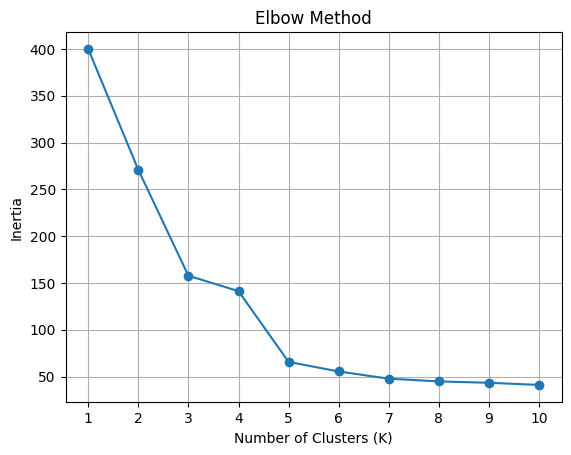

In [14]:
# Store inertia for each K
inertia = []

# Test K values from 1 to 10
for k in range(1, 11):

    # Initialize K centroids randomly from data points
    np.random.seed(42)
    centroids = X_scaled[np.random.choice(len(X_scaled), k, replace=False)]

    # Repeat assignment and centroid calculation
    for iteration in range(100):

        # Calculate Euclidean distance from every point to every centroid
        distances = np.sqrt(
            ((X_scaled[:, np.newaxis, :] -
              centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
        )

        # Assign each point to the nearest centroid
        labels = np.argmin(distances, axis=1)

        # Recalculate centroids using the mean formula
        new_centroids = np.array([
            X_scaled[labels == i].mean(axis=0)
            if np.any(labels == i) else centroids[i]
            for i in range(k)
        ])

        # Stop if centroids no longer change
        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    # Calculate inertia: sum of squared distances to assigned centroids
    inertia.append(np.sum(
        (X_scaled - centroids[labels]) ** 2
    ))

# Plot the Elbow graph
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [15]:
# Select K based on the Elbow graph
k = 5

# Initialize K centroids randomly from the dataset
np.random.seed(42)
centroids = X_scaled[np.random.choice(len(X_scaled), k, replace=False)]

# Repeat until centroids converge or 100 iterations are completed
for iteration in range(100):

    # Step 1: Calculate Euclidean distance
    # d = sqrt((x1-c1)^2 + (x2-c2)^2)
    distances = np.sqrt(
        ((X_scaled[:, np.newaxis, :] -
          centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
    )

    # Step 2: Assign each point to its nearest centroid
    labels = np.argmin(distances, axis=1)

    # Step 3: Recalculate centroid using the mean formula
    # New centroid = sum of points in cluster / number of points
    new_centroids = np.array([
        X_scaled[labels == i].mean(axis=0)
        if np.any(labels == i) else centroids[i]
        for i in range(k)
    ])

    # Step 4: Stop if centroids do not change
    if np.allclose(centroids, new_centroids):
        print("Centroids converged")
        centroids = new_centroids
        break

    # Update centroids for the next iteration
    centroids = new_centroids

# Store cluster labels in the dataset
df['Cluster'] = labels

# Convert centroids back to the original units
centroids_original = centroids * std + mean

print("Cluster counts:")
print(df['Cluster'].value_counts().sort_index())

print("\nCentroids (original units):")
print(centroids_original)

Centroids converged
Cluster counts:
Cluster
0    80
1    22
2    23
3    39
4    36
Name: count, dtype: int64

Centroids (original units):
[[55.0875     49.7125    ]
 [25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [86.53846154 82.12820513]
 [87.75       17.58333333]]


In [16]:
# Calculate distances for the first five data points
sample_distances = np.sqrt(
    ((X_scaled[:5, np.newaxis, :] -
      centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
)

# Display distances from each point to all centroids
print("Distances from first five customers to each centroid:")
print(np.round(sample_distances, 3))

# Display the nearest centroid for each sample
print("\nAssigned cluster:")
print(np.argmin(sample_distances, axis=1))

Distances from first five customers to each centroid:
[[1.586 1.62  0.824 3.203 2.899]
 [1.954 0.414 2.372 2.731 3.711]
 [2.26  2.872 0.7   3.998 2.775]
 [1.83  0.382 2.213 2.7   3.581]
 [1.502 1.564 0.822 3.118 2.837]]

Assigned cluster:
[2 1 2 1 2]


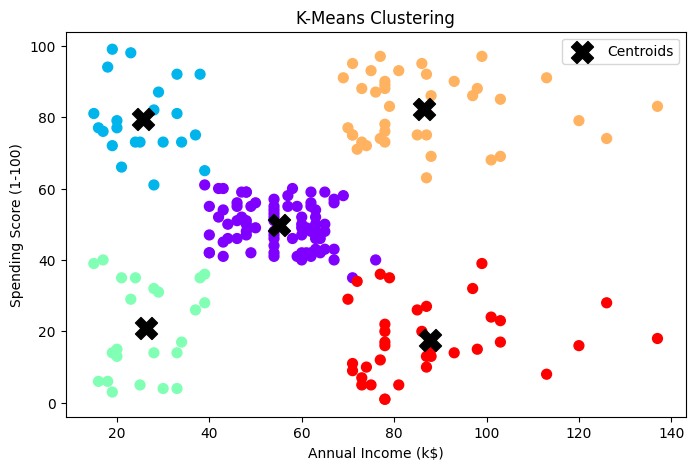

In [17]:
# Plot customer clusters using original feature values
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0], X[:, 1],
    c=labels, cmap='rainbow', s=50
)

# Mark the centroids
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    marker='X', s=250, color='black',
    label='Centroids'
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Clustering")
plt.legend()
plt.show()